# 01 随机投点法 Hit-or-miss method

## 1. 算法介绍



随机投点法是一种基于随机数的数值计算方法，也属于蒙特卡洛方法的一种。

它的基本思想是：在一个已知区域内随机生成大量点，通过统计落入目标区域中的点数比例，来估计目标区域的面积或相关数值。

假设：

- 总随机点数为 $N$
- 落入目标区域的点数为 $M$
- 外部区域面积为 $S$

则目标区域面积可以近似表示为：

$$
S_{\text{目标}} \approx S\frac{M}{N}
$$

## 2. 数学原理



随机投点法的核心依据是：**当随机点在一个区域内均匀分布时，点落入某个子区域的概率，等于这个子区域面积占总区域面积的比例。**

设外部区域为 $R$，面积为 $S_R$；目标区域为 $A$，面积为 $S_A$。

如果在区域 $R$ 内均匀随机生成一个点，那么这个点落入目标区域 $A$ 的概率为：

$$
P=\frac{S_A}{S_R}
$$

也就是说，目标区域面积占总面积的比例，就是随机点落入目标区域的概率。

现在在区域 $R$ 中随机生成 $N$ 个点，其中有 $M$ 个点落入目标区域 $A$。

那么实际实验中，随机点落入目标区域的频率为：

$$
\frac{M}{N}
$$

根据大数定律，当随机点数量 $N$ 足够大时，实验频率会逐渐接近真实概率，因此有：

$$
\frac{M}{N}\approx P
$$

又因为：

$$
P=\frac{S_A}{S_R}
$$

所以：

$$
\frac{M}{N}\approx\frac{S_A}{S_R}
$$

整理可得：

$$
S_A\approx S_R\frac{M}{N}
$$

这就是随机投点法的基本公式。

假设要求计算：

$$
I=\int_a^b f(x)\,dx
$$

并且函数满足 $0\leq f(x)\leq h$。

可以用一个宽为 $b-a$、高为 $h$ 的矩形将函数图像下方的区域包围起来。

矩形面积为：

$$
S_R=(b-a)h
$$

在这个矩形内随机生成 $N$ 个点，其中有 $M$ 个点满足：

$$
y\leq f(x)
$$

说明这些点落在函数曲线下方。

因此，曲线下方面积与矩形面积的比例可以近似为：

$$
\frac{\int_a^b f(x)\,dx}{(b-a)h}
\approx
\frac{M}{N}
$$

于是得到：

$$
\int_a^b f(x)\,dx
\approx
(b-a)h\frac{M}{N}
$$

## 3. 导入相关库

In [13]:
import numpy as np
import matplotlib.pyplot as plt

## 4. 手动实现

In [14]:
N = 1000
a = 1
b = 2
h = 4

x = np.random.uniform(a, b, N)
y = np.random.uniform(0, h, N)

fx = x**2

inside = y <= fx
M = np.sum(inside)

S = (b-a) * h
I = S * M / N
print("积分估计值：", I)

积分估计值： 2.272


## 5. 可视化

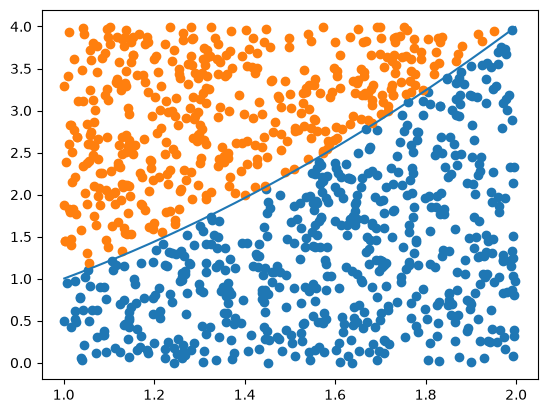

In [ ]:
index = np.argsort(x)

plt.scatter(x[inside], y[inside], label="inside")
plt.scatter(x[~inside], y[~inside], label="outside")
plt.plot(x[index], fx[index])
plt.show()

## 6.python新知识

1.x = np.random.uniform(a, b, N):生成N个均匀分布的随机点

2.inside = y <= fx:(y <= fx)得到一个布尔变量，<=运算级比=高，先算。且布尔数据可直接看作0/1进行数学运算

3.plt.show():后面记得加括号

4.plt.plot(横坐标, 纵坐标)会按照数组中的顺序连线，所以画函数曲线时，通常让 x 有序。index = np.argsort(x)：生成排序后的下标。arg一般都生成下标

5.np.linspace(1, 2, 5)结果是：[1.   1.25 1.5  1.75 2.  ]，用于生成均匀的数

6.分别生成两种点可以更好的区分。例如plt.scatter(x[inside], y[inside], label="inside")和plt.scatter(x[~inside], y[~inside], label="outside")